# Hangman strategy explorer

Compare the hangman strategies from `strategy.py`, `optimal.py` and `winprob.py`
on one word length under a chosen word distribution. Pick a `LENGTH`, a
`WEIGHTING` (how likely each word is to be the secret word) and a `STRATEGY`,
then re-run the rest: the opener, hardest words, per-guess tree, and how the
headline number scales with length all follow your choice.

Reminders: a *miss* is a wrong letter guess. `optimal`/`winprob` replay the
solvers' committed trees, so they only cover length/weighting combinations that
have already been solved -- others report cleanly instead of erroring.

In [1]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'strategy.py').exists():
            return c
    raise FileNotFoundError('Could not find strategy.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import strategy
import strategy_view as sview
import wordlist

pd.set_option('display.max_rows', 200)   # show up to 200 rows before pandas truncates to a head/tail preview

print(f'imported strategy + strategy_view from {math_dir}')

imported strategy + strategy_view from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Pick length, distribution, and strategy

Change `LENGTH`, `WEIGHTING`, `STRATEGY` (and `BUDGET`, for winprob;
`FILL_CAPPED`, for optimal), then re-run the rest.

`WEIGHTING` -- how likely each word is to be the secret word:
- `"uniform"` -- every word equally likely.
- `"zipf"` -- real English frequency (common words weigh more).
- `"greedy"` / `"best_opener"` -- the adversarial word-setter from `freq_search.py`
  (per-(letter,pattern) multipliers), tuned to make that guesser work hardest.
- `"greedy_word"` / `"best_opener_word"` -- the newer *per-word* frequency adversary.

`STRATEGY` -- the guesser:
- `"greedy"` -- guess the highest combined-frequency un-guessed letter (live, any weighting).
- `"greedy_best"` -- force the best first letter, then greedy (live, any weighting).
- `"optimal"` -- minimise expected misses (replays `data/shared/optimal/`).
- `"winprob"` -- maximise P(win within `BUDGET` misses) (replays `data/shared/winprob/`).

`FILL_CAPPED` (optimal only) -- when an optimal solve has **not converged**, its
committed tree truncates the hardest branches at the miss cap (leaves marked
*capped*). With `FILL_CAPPED=True` (default) those branches are finished with
**greedy** -- optimal above the cap, greedy below -- so every word resolves and the
headline `avg_misses` is the *greedy-completed upper bound* on the true optimum
(`summary()['greedy_finished']` counts the completed words). With
`FILL_CAPPED=False` the capped words stay unresolved and the headline averages only
the fully-optimal words (a lower, optimistic partial). Converged solves ignore this
flag (they have no capped branches).

`make_strategy` returns one uniform `sv` that every cell below uses. `optimal`
and `winprob` exist only for solved length/weighting combos; when one is missing,
`sv.available` is `False` and `sv.note` says what to run -- the cells skip cleanly.

In [2]:
LENGTH    = 5           # <-- word length
WEIGHTING = "uniform"   # <-- uniform, zipf, greedy, best_opener, greedy_word, best_opener_word
STRATEGY  = "optimal"    # <-- greedy, greedy_best, optimal, winprob
BUDGET    = None         # <-- winprob only: miss budget k (None = most permissive solved)
FILL_CAPPED = True       # <-- optimal only: finish cap-truncated branches with greedy (see note)

g  = strategy.GreedyGame(LENGTH)
sv = sview.make_strategy(STRATEGY, LENGTH, weighting=WEIGHTING, budget=BUDGET,
                         fill_capped=FILL_CAPPED, game=g)

print(f'{g.N:,} words of length {LENGTH}  (zipf >= {wordlist.DEFAULT_ZIPF})')
print(f'weighting: {WEIGHTING}   strategy: {sv.label}')
if not sv.available:
    print(f'\n!! not available: {sv.note}')
else:
    print(f'opener: {sv.opener()!r}')
    hv = sv.headline_value()
    print(f'{sv.headline_label()}: ' + (f'{hv:.4f}' if hv is not None else 'n/a'))
    for k, v in sv.summary().items():
        print(f'  {k}: {v}')
    if sv.note:
        print(f'note: {sv.note}')

3,495 words of length 5  (zipf >= 2.5)
weighting: uniform   strategy: optimal (uniform, cap 7*+greedy)
opener: 'e'
avg misses: 3.8758
  opener: e
  note: capped approximation, greedy-completed: deepest committed cap is 7; branches truncated at the cap are finished with greedy (optimal above the cap, greedy below), so every word resolves. The headline avg is the greedy-completed UPPER bound on the true optimum (optimal.py's `upper` column); the true optimum is <= it. Set FILL_CAPPED=False for the raw capped view.
  avg_misses: 3.8758226037195995
  capped: 0
  greedy_finished: 287
note: capped approximation, greedy-completed: deepest committed cap is 7; branches truncated at the cap are finished with greedy (optimal above the cap, greedy below), so every word resolves. The headline avg is the greedy-completed UPPER bound on the true optimum (optimal.py's `upper` column); the true optimum is <= it. Set FILL_CAPPED=False for the raw capped view.


## Best opening letters

Expected misses if each letter is forced as the first guess and the guesser plays
on; the dashed line marks the best (its own opener). This forced-opener sweep is
greedy-family only -- for `optimal`/`winprob` it would need a re-solve per opener
(not cached), so those print a short note instead.

In [3]:
by_letter = sv.misses_by_starting_letter() if sv.available else None
if by_letter is None:
    print(f'{sv.label}: forced-opener sweep is greedy-family only.')
    if sv.available:
        print(f'(this strategy opens with {sv.opener()!r})')
else:
    mb = pd.Series(by_letter, name='avg_misses'); mb.index.name = 'first_letter'
    op = sv.opener()
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.bar(mb.index, mb.values, color='#3b6ea5')
    ax.axhline(mb[op], color='#cc4444', ls='--', lw=1, label=f'{sv.label} opener {op!r}')
    ax.set_ylabel('avg misses')
    ax.set_title(f'Expected misses by opening letter (length {LENGTH}, {WEIGHTING})')
    ax.legend(); plt.show()
    display(mb.to_frame().T)

optimal (uniform, cap 7*+greedy): forced-opener sweep is greedy-family only.
(this strategy opens with 'e')


## Per-word difficulty

How many misses the strategy makes on each word, and the distribution. Words the
strategy leaves *unresolved* -- `optimal` words capped past the solved depth, or
`winprob` words that can't be won within the budget -- have no finite miss count
and are tallied separately (they sort to the top of the hardest list).

solved with 0 misses: 104 words
max misses: 12   mean (resolved): 3.876
greedy-completed (capped branch finished with greedy): 287 words


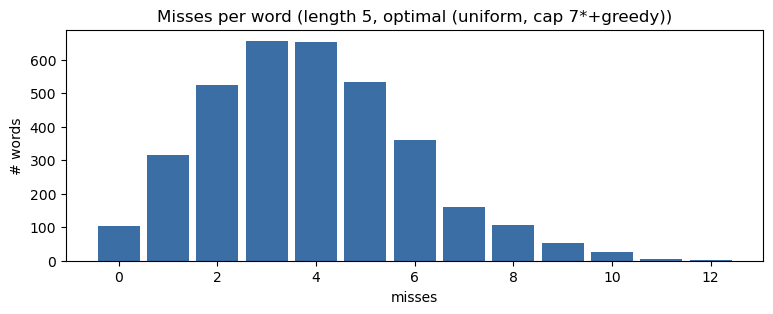

hardest words:


,word,misses
0,worry,12.0
1,gully,12.0
2,wills,11.0
3,hurry,11.0
4,ruddy,11.0
5,fuzzy,11.0
6,poppy,11.0
7,jokes,11.0
8,pills,10.0
9,bunny,10.0


In [4]:
if not sv.available:
    print('not available:', sv.note)
else:
    pwm = sv.per_word_misses()
    status = sv.per_word_status()
    resolved = pwm[~np.isnan(pwm)]
    n_unres = int(np.isnan(pwm).sum())
    words = pd.DataFrame({'word': g.words, 'misses': pwm})

    print(f'solved with 0 misses: {int((resolved == 0).sum()):,} words')
    hi = int(resolved.max()) if resolved.size else 0
    print(f'max misses: {hi}   mean (resolved): {resolved.mean():.3f}')
    if n_unres:
        kind = 'capped' if sv.kind == 'optimal' else 'lost (over budget)'
        print(f'unresolved ({kind}): {n_unres:,} words')
    n_greedy = int((status == 3).sum())
    if n_greedy:
        print(f'greedy-completed (capped branch finished with greedy): {n_greedy:,} words')

    fig, ax = plt.subplots(figsize=(9, 3))
    if resolved.size:
        ax.hist(resolved, bins=range(0, hi + 2), color='#3b6ea5', align='left', rwidth=0.85)
    ax.set_xlabel('misses'); ax.set_ylabel('# words')
    ax.set_title(f'Misses per word (length {LENGTH}, {sv.label})')
    plt.show()

    print('hardest words:')
    display(words.sort_values('misses', ascending=False, na_position='first')
                 .head(12).reset_index(drop=True))

## Trace one word

The actual guess sequence for a word under the current strategy: each guess and
whether it hit. Defaults to the hardest resolved word; set `WORD` yourself to
trace another.

In [5]:
if not sv.available:
    print('not available:', sv.note)
else:
    pwm = sv.per_word_misses()
    WORD = g.words[int(np.argsort(np.where(np.isnan(pwm), -1.0, pwm))[-1])]  # hardest resolved
    # WORD = 'bench'   # <-- or pick your own

    hits = sv.trace(WORD)
    n_miss = sum(1 for _, hit in hits if not hit)
    print(f'{WORD!r}: {n_miss} misses  ({sv.label})')
    for letter, hit in hits:
        print(f'  {letter}  ' + ('hit ' if hit else 'MISS'))
    if not hits:
        print('  (the strategy leaves this word unresolved)')

'worry': 12 misses  (optimal (uniform, cap 7*+greedy))
  e  MISS
  a  MISS
  o  hit 
  s  MISS
  t  MISS
  d  MISS
  c  MISS
  g  MISS
  y  hit 
  l  MISS
  b  MISS
  k  MISS
  m  MISS
  p  MISS
  r  hit 
  w  hit 


## Inspect a tree node

Give a board (revealed letters + `_` blanks, e.g. `"b_ll_"`) and the missed
letters; `show_state` finds that node in the current strategy's tree: the
candidates remaining, the next guess, and every outcome it can produce. States
the strategy never reaches are flagged. A hit reveals **all** positions of a
letter, so put every occurrence of a revealed letter on the board.

In [6]:
def show_state(board, missed=""):
    """Locate `board` (+ missed letters) in the current strategy `sv`'s tree and
    print its next guess and every outcome that guess can lead to."""
    if not sv.available:
        print('not available:', sv.note); return None
    st = sv.state(board, missed)
    tag = 'reachable' if st.get('reachable') else 'NOT REACHED'
    print(f"board {st['board']!r}   missed [{','.join(st['missed'])}]   ({tag})  [{sv.label}]")
    if not st.get('reachable'):
        print(f"  {st.get('reason')}"); return st
    if st['determined']:
        w = st['candidates'][0] if st['candidates'] else '(none)'
        print(f"  word determined: {w}"); return st
    print(f"  {st['n']} candidates, e.g. {', '.join(st['candidates'][:8])}")
    print(f"  guesses: {st['guess']!r}")
    for o in st['outcomes']:
        kind = 'HIT ' if o['hit'] else 'miss'
        print(f"    {kind} -> {o['board']!r}  ({o['n']:>4} words)  e.g. {', '.join(o['sample'][:5])}")
    return st

# the opener: the outcomes of the strategy's first guess (empty board)
_ = show_state('_____')

board '_____'   missed []   (reachable)  [optimal (uniform, cap 7*+greedy)]
  3495 candidates, e.g. about, their, there, which, would, other, after, first
  guesses: 'e'
    miss -> '_____'  (1856 words)  e.g. about, which, would, first, think
    HIT  -> 'e____'  (  39 words)  e.g. early, enjoy, earth, eight, extra
    HIT  -> '_e___'  ( 282 words)  e.g. years, being, least, means, death
    HIT  -> '__e__'  ( 144 words)  e.g. their, great, check, clear, field
    HIT  -> 'e_e__'  (  13 words)  e.g. every, event, enemy, elect, erect
    HIT  -> '_ee__'  (  41 words)  e.g. needs, seems, weeks, feels, keeps
    HIT  -> '___e_'  ( 587 words)  e.g. other, after, under, money, women
    HIT  -> 'e__e_'  (  21 words)  e.g. ended, enter, eaten, edges, elder
    HIT  -> '_e_e_'  (  38 words)  e.g. never, level, seven, peter, refer
    HIT  -> '__ee_'  (  41 words)  e.g. green, sleep, speed, sweet, queen
    HIT  -> '____e'  ( 356 words)  e.g. those, while, state, since, house
    HIT  -> 'e__

## All situations at depth k

Every node the strategy can reach after exactly `k` guesses, with the choice it
makes there. Depth 0 is the opener; at depth `k`, `k` guesses are in and `guess`
is the next one. Branches already resolved by depth `k` show `guess = None`.

In [7]:
DEPTH = 3      # <-- number of guesses already made

if not sv.available:
    print('not available:', sv.note); sit = pd.DataFrame()
else:
    sit = pd.DataFrame(sv.states_at_depth(DEPTH))
    if len(sit):
        sit['missed'] = sit['missed'].apply(''.join)
        sit['sample'] = sit['sample'].apply(lambda s: ' '.join(s[:4]))
        live = sit[~sit['determined']]
        print(f'depth {DEPTH}: {len(sit)} nodes  ({len(live)} still undetermined)  [{sv.label}]')
        if len(live):
            spread = ', '.join(f'{k}={v}' for k, v in live['guess'].value_counts().items())
            print(f'next guess spread: {spread}')
        display(sit.sort_values('n', ascending=False).head(50).reset_index(drop=True))
    else:
        print(f'no nodes at depth {DEPTH}')

depth 3: 255 nodes  (178 still undetermined)  [optimal (uniform, cap 7*+greedy)]
next guess spread: s=21, i=19, a=15, n=14, d=14, r=13, t=13, l=12, g=7, p=7, c=7, m=6, w=5, o=5, h=5, u=4, k=3, y=2, b=2, x=1, v=1, f=1, j=1


,board,missed,n,fmass,determined,guess,sample
0,_____,aeo,547,547.0,False,i,which first think right
1,_o___,ae,205,205.0,False,s,would could going world
2,_a___,et,200,200.0,False,s,happy major march hands
3,___e_,rs,177,177.0,False,d,money women video given
4,___es,r,137,137.0,False,a,times makes games comes
5,__o__,ae,129,129.0,False,s,group story known wrong
6,_e___,rt,114,114.0,False,l,being means media legal
7,____e,ao,108,108.0,False,i,while since white quite
8,__a__,es,88,88.0,False,r,thank black board crazy
9,___er,a,74,74.0,False,i,other under power lower


In [8]:
sit['guess'].value_counts() if len(sit) else 'no nodes at this depth'

s    21
i    19
a    15
n    14
d    14
r    13
t    13
l    12
g     7
p     7
c     7
m     6
w     5
o     5
h     5
u     4
k     3
y     2
b     2
x     1
v     1
f     1
j     1
Name: guess, dtype: int64

## Guess frequency at a level (across all word lengths)

`guesses_at_level(level)` tallies, over **every word length**, how often each
letter is the strategy's next guess at a given `level` (= depth, guesses already
made: `level=0` is the opener, `level=1` the second guess, ...). One row per
letter, sorted by **`freq_words`**:

- **n_situations** -- how many distinct reachable boards (across all lengths)
  prompt that letter as the next guess at this level,
- **n_words** -- raw words those situations cover,
- **freq_words** -- frequency-weighted word count. Each situation contributes
  *(its frequency share of its length)* × *(words at that length)* =
  `fmass / total_freq_L * N_L`, where `fmass` is the summed weight of the
  situation's words. This **equals `n_words` under `uniform`** (so the ranking is
  unchanged there); under a real weighting (`zipf`, the adversaries) it up-weights
  the letter-patterns that hold the *common* words, while keeping every length on a
  comparable "effective words" scale,
- **situations** -- every board, labelled `len:board[/missed] (freq_words | n)`,
  sorted by `freq_words` descending.

> **At `level=0` (the opener) `freq_words` is always equal to `n_words`** -- and
> that is correct, not a bug. There is one situation per length: the *empty board*,
> which covers **every** word, so its frequency share is 100% and
> `freq_words = total_freq_L/total_freq_L * N_L = N_L = n_words`, for *every*
> weighting. The weighting only moves the numbers at `level>=1`, where the
> situations partition the words -- bump `LEVEL` to 1+ to see it take effect.

Uses the current `STRATEGY`/`WEIGHTING`/`BUDGET`/`FILL_CAPPED`; word lengths with
no committed solve for this strategy are skipped cleanly. Determined branches
(word already known, so no guess) are not counted.

In [9]:
LEVEL = 20 # <-- guesses already made: 0 = opener, 1 = second guess, ...

def guesses_at_level(level, lengths=range(1, 21), *, strategy=STRATEGY,
                     weighting=WEIGHTING, budget=BUDGET, fill_capped=FILL_CAPPED):
    """Per-letter tally of the strategy's next guess at `level`, aggregated across
    every word length. One row per letter, sorted by `freq_words` (descending):

      n_situations -- distinct reachable boards (across all lengths) prompting it,
      n_words      -- raw words those situations cover,
      freq_words   -- frequency-weighted word count: each situation contributes
                      (its frequency share of its length) * (words at that length),
                      i.e. fmass / total_freq_L * N_L. Equals n_words under uniform.
      situations   -- every board, `len:board[/missed] (freq_words | n)`, sorted by
                      freq_words descending.

    Situations with exactly zero frequency mass (all their words weigh 0 under the
    weighting, so freq_words would be 0) are dropped from all three columns; a
    letter left with none is omitted. Lengths with no committed solve are skipped;
    determined branches (no guess) are ignored."""
    rows = {}
    for L in lengths:
        s = sview.make_strategy(strategy, L, weighting=weighting, budget=budget,
                                fill_capped=fill_capped)
        if not s.available:
            continue
        total = float(s.word_freq().sum())
        scale = (s.g.N / total) if total else 0.0      # freq share -> effective words
        for st in s.states_at_depth(level):
            if st['determined'] or st['fmass'] == 0.0:  # skip resolved & zero-freq boards
                continue
            fw = st['fmass'] * scale
            missed = ''.join(st['missed'])
            label = f"{L:>2}:{st['board']}" + (f"/{missed}" if missed else "")
            rows.setdefault(st['guess'], []).append((label, st['n'], fw))
    out = []
    for letter, sits in rows.items():
        sits.sort(key=lambda t: t[2], reverse=True)
        out.append({'letter': letter,
                    'n_situations': len(sits),
                    'n_words': sum(n for _, n, _ in sits),
                    'freq_words': sum(fw for _, _, fw in sits),
                    'situations': [f'{lab} ({fw:.1f} | {n})' for lab, n, fw in sits]})
    if not out:
        return pd.DataFrame(columns=['letter', 'n_situations', 'n_words',
                                     'freq_words', 'situations'])
    return (pd.DataFrame(out).sort_values('freq_words', ascending=False)
              .reset_index(drop=True))

tbl = guesses_at_level(LEVEL)
print(f'level {LEVEL} (guess #{LEVEL + 1}): {len(tbl)} distinct letters  '
      f'[{STRATEGY} / {WEIGHTING}]')
with pd.option_context('display.max_colwidth', None):
    display(tbl)

level 20 (guess #21): 0 distinct letters  [optimal / uniform]


,letter,n_situations,n_words,freq_words,situations


## Where one letter is guessed (single length)

`guesses_of_letter(letter, length)` finds **every** situation -- a reachable board
with **nonzero probability** under the weighting -- at `length` where the
strategy's next guess is `letter`, sorted by **level** (depth = guesses already
made) then by **freq_words** (descending). Columns:

- **level** -- guesses already made when this board is reached (0 = opener),
- **board** / **missed** -- the revealed board and the missed letters there,
- **n_words** -- words consistent with that board,
- **freq_words** -- frequency-weighted words (`fmass / total_freq_L * N_L`, same
  units as the table above); for a single length this is just a scaling of the raw
  frequency mass, so it's also the sort key within each level,
- **sample** -- a few example candidate words at that board,
- **hit_sample** -- a few candidates that actually **contain `letter`** -- the
  words this guess would reveal (a hit).

Boards whose words all weigh 0 under the weighting are skipped (nonzero-prob
only). Uses the current `STRATEGY`/`WEIGHTING`/`BUDGET`/`FILL_CAPPED`.

In [14]:
LETTER   = 'u'       # <-- the guessed letter to locate
WORD_LEN = LENGTH    # <-- word length (defaults to the LENGTH picked at the top)

def guesses_of_letter(letter, length, *, strategy=STRATEGY, weighting=WEIGHTING,
                      budget=BUDGET, fill_capped=FILL_CAPPED, max_level=40,
                      verbose=True):
    """Every situation at `length` where the strategy's next guess is `letter` and
    the board has nonzero probability under the weighting, sorted by level (depth)
    then freq_words (descending). Columns: level, board, missed, n_words,
    freq_words (= fmass / total_freq_L * N_L, as in guesses_at_level), sample (any
    candidates there), hit_sample (candidates that CONTAIN `letter` -- the words
    this guess would reveal). Determined branches (no guess) and zero-frequency
    boards are skipped. `verbose=False` silences the skip/empty notes (used by the
    all-lengths sweep below)."""
    letter = letter.lower()
    cols = ['level', 'board', 'missed', 'n_words', 'freq_words', 'sample', 'hit_sample']
    s = sview.make_strategy(strategy, length, weighting=weighting, budget=budget,
                            fill_capped=fill_capped)
    if not s.available:
        if verbose:
            print('not available:', s.note)
        return pd.DataFrame(columns=cols)
    total = float(s.word_freq().sum())
    scale = (s.g.N / total) if total else 0.0          # freq share -> effective words
    rows = []
    for level in range(max_level + 1):
        nodes = s.states_at_depth(level)
        if not nodes:                                   # tree bottomed out
            break
        for st in nodes:
            if st['determined'] or st['guess'] != letter or st['fmass'] == 0.0:
                continue
            missed = ''.join(st['missed'])
            cand = s.state(st['board'], missed).get('candidates', [])
            hit = [w for w in cand if letter in w]      # words this guess reveals
            rows.append({'level': level, 'board': st['board'], 'missed': missed,
                         'n_words': st['n'], 'freq_words': st['fmass'] * scale,
                         'sample': ' '.join(st['sample'][:5]),
                         'hit_sample': ' '.join(hit[:5])})
    if not rows:
        if verbose:
            print(f'{letter!r} is never the next guess at a nonzero-probability board '
                  f'(length {length}, {s.label})')
        return pd.DataFrame(columns=cols)
    return (pd.DataFrame(rows)
              .sort_values(['level', 'freq_words'], ascending=[True, False])
              .reset_index(drop=True))

res = guesses_of_letter(LETTER, WORD_LEN)
print(f'{LETTER!r} at length {WORD_LEN}: {len(res)} situations  [{STRATEGY} / {WEIGHTING}]')
with pd.option_context('display.max_colwidth', None):
    display(res)

'u' at length 5: 40 situations  [optimal / uniform]


,level,board,missed,n_words,freq_words,sample,hit_sample
0,3,_a__t,e,12,12.0,fault paint saint habit waist,fault vault haunt gaunt gamut
1,3,_et__,l,8,8.0,metro setup retro fetch fetus,setup fetus getup
2,3,__est,,5,5.0,guest chest quest crest wrest,guest quest
3,3,e__de,l,4,4.0,evade erode etude exude,etude exude
4,4,_____,aeio,213,213.0,study stuff trust truth funny,study stuff trust truth funny
5,4,____e,aio,35,35.0,style judge cycle uncle nurse,judge uncle nurse curve curse
6,4,___i_,aeo,26,26.0,until music split fruit strip,until music fruit fluid pupil
7,4,____a,eio,10,10.0,ultra junta hydra scuba supra,ultra junta scuba supra cuppa
8,4,a___e,io,9,9.0,apple abuse argue angle acute,abuse argue acute azure amuse
9,4,____o,aei,7,7.0,dunno turbo hydro jumbo gusto,dunno turbo jumbo gusto dumbo


## Where one letter is guessed (all lengths)

`guesses_of_letter_all_lengths(letter)` is the same as above but swept over
**every word length**: every situation (at any length) where the strategy's next
guess is `letter` and the board has nonzero probability, sorted by **level**, then
**length**, then **freq_words** (descending). It adds a `length` column; because
`freq_words` is the cross-length-comparable metric (`fmass / total_freq_L * N_L`),
situations from different lengths sit on the same scale and sort together. Lengths
with no committed solve are skipped. Uses the current
`STRATEGY`/`WEIGHTING`/`BUDGET`/`FILL_CAPPED`.

In [15]:
def guesses_of_letter_all_lengths(letter, lengths=range(1, 21), *,
                                  strategy=STRATEGY, weighting=WEIGHTING,
                                  budget=BUDGET, fill_capped=FILL_CAPPED):
    """`guesses_of_letter` swept over every word length: every situation (any
    length) where the strategy's next guess is `letter` and the board has nonzero
    probability, sorted by level, then length, then freq_words (descending). Adds a
    `length` column; `freq_words` is the cross-length-comparable metric
    (fmass / total_freq_L * N_L), so situations from different lengths sort together."""
    cols = ['level', 'length', 'board', 'missed', 'n_words', 'freq_words',
            'sample', 'hit_sample']
    parts = []
    for L in lengths:
        df = guesses_of_letter(letter, L, strategy=strategy, weighting=weighting,
                               budget=budget, fill_capped=fill_capped, verbose=False)
        if len(df):
            df.insert(1, 'length', L)
            parts.append(df)
    if not parts:
        print(f'{letter.lower()!r} is never guessed at any length  [{strategy} / {weighting}]')
        return pd.DataFrame(columns=cols)
    return (pd.concat(parts, ignore_index=True)
              .sort_values(['level', 'length', 'freq_words'],
                           ascending=[True, True, False])
              .reset_index(drop=True))

res_all = guesses_of_letter_all_lengths(LETTER)
print(f'{LETTER!r}, all lengths: {len(res_all)} situations  [{STRATEGY} / {WEIGHTING}]')
with pd.option_context('display.max_colwidth', None):
    display(res_all.head(200))

'u', all lengths: 372 situations  [optimal / uniform]


,level,length,board,missed,n_words,freq_words,sample,hit_sample
0,1,8,___ee_e_,,4,4.0,screened squeezed squeezes unneeded,squeezed squeezes unneeded
1,1,10,_____e_ee_,,2,2.0,unforeseen tumbleweed,unforeseen tumbleweed
2,1,13,_____i_______,,8,8.0,consciousness autobiography acquaintances complimentary unequivocally,consciousness autobiography acquaintances unequivocally conspicuously
3,2,4,t__a,,3,3.0,tuna tuba toga,tuna tuba
4,2,6,_se___,,2,2.0,useful pseudo,useful pseudo
5,2,7,_e___re,,13,13.0,feature measure welfare venture lecture,feature measure venture lecture texture
6,2,7,__s__es,,7,7.0,muscles castles mosques huskies insides,muscles mosques huskies insures
7,2,7,_____ee,n,4,4.0,trustee jubilee marquee amputee,trustee jubilee marquee amputee
8,2,8,_e___re_,,21,21.0,features measures declared featured measured,features measures featured measured lectures
9,2,8,s____se_,,3,3.0,supposed surmised suffused,supposed surmised suffused


## Summary for a set of guessed letters

`letters_summary(letters)` takes a collection of `letters` (a string; case, dupes
and non-letters are ignored) treated as **already guessed**, and reports over the
current `LENGTH`'s word list a word **count** and **total frequency** (the
weighting's `fmass`, and its % of all words/frequency) for three categories:

- **only these letters** — words spelled entirely from `letters` (so fully revealed
  once all are guessed);
- **uniquely determined after** — words whose revealed pattern of `letters` (which of
  them sit at which positions, blanks elsewhere) is shared by no other word, so
  guessing `letters` already pins the word down;
- **strategy solves miss-free after** — words the strategy resolves with **zero
  further misses** once `letters` have all been guessed.

These nest: *only-these-letters* ⊆ *uniquely-determined* ⊆ *miss-free*. More
categories can be bolted on later.

> **Miss-free semantics (force-guessed).** We **force-guess** all of `letters` — reaching
> the board where each is revealed (or known absent; absent ones are misses *during*
> that phase, which don't count) — and then **finish greedily**, counting words that
> need no further wrong guess. For the `greedy`/`greedy_best` strategies this greedy
> finish IS the strategy; for `optimal`/`winprob` the continuation from an arbitrary
> forced state isn't in the committed tree, so the finish is greedy (greedy-below-`L`,
> the same convention as `FILL_CAPPED`). Say if you'd rather it use the selected
> strategy's own play order instead of a forced-`L`-first model.

In [ ]:
GUESSED_LETTERS = 'etaoinrs'   # <-- letters treated as already guessed (case/dupes/non-letters ignored)

def _greedy_missfree_after(g, freq, wi, Lidx, guessed0):
    """True iff, after force-guessing the letters `Lidx` (bitmask `guessed0`), a
    GREEDY play finishes word `wi` from its L-signature candidate set with no
    further miss (i.e. greedy never guesses a letter absent from `wi`)."""
    m = g.masks
    S = np.arange(g.N)
    for c in Lidx:                                  # candidates sharing wi's L-reveal
        S = S[m[S, c] == m[wi, c]]
    guessed = guessed0
    while S.shape[0] > 1:
        lf = freq[S] @ g.present[S]                 # greedy score: freq-weighted presence
        gg = guessed
        while gg:                                   # mask already-guessed letters
            c0 = (gg & -gg).bit_length() - 1
            lf[c0] = -1.0
            gg &= gg - 1
        c = int(lf.argmax())
        if lf[c] < 0:
            break
        if not m[wi, c]:                            # greedy guesses a letter absent from wi -> miss
            return False
        S = S[m[S, c] == m[wi, c]]
        guessed |= (1 << c)
    return True

def letters_summary(letters, *, strategy=STRATEGY, length=LENGTH, weighting=WEIGHTING,
                    budget=BUDGET, fill_capped=FILL_CAPPED):
    """Count + total frequency (the weighting's fmass) of length-`length` words that
    (1) contain only `letters`, (2) are uniquely determined once `letters` are
    guessed, (3) the strategy finishes with no further miss after `letters` are
    force-guessed. See the markdown above for the miss-free semantics + caveats."""
    s = sview.make_strategy(strategy, length, weighting=weighting, budget=budget,
                            fill_capped=fill_capped)
    if not s.available:
        print('not available:', s.note)
        return pd.DataFrame()
    g, freq, words = s.g, s.word_freq(), s.g.words
    Lset = {c for c in letters.lower() if c.isalpha()}
    Lidx = {ord(c) - 97 for c in Lset}
    guessed0 = 0
    for c in Lidx:
        guessed0 |= (1 << c)

    # (1) words spelled entirely from L
    outside = [c for c in range(26) if c not in Lidx]
    only_L = (g.present[:, outside].sum(axis=1) == 0) if Lidx else np.zeros(g.N, bool)

    # (2) unique L-signature (L-letters at their positions, '_' elsewhere)
    sigs = [''.join(ch if ch in Lset else '_' for ch in w) for w in words]
    counts = pd.Series(sigs).value_counts()
    uniq = np.array([counts[si] == 1 for si in sigs])

    # (3) strategy (greedy-finished) resolves miss-free after force-guessing L
    status = s.per_word_status()                    # 1 capped / 2 lost -> unsolved
    missfree = np.array([False if status[i] in (1, 2)
                         else _greedy_missfree_after(g, freq, i, Lidx, guessed0)
                         for i in range(g.N)])

    tot_n, tot_f = g.N, float(freq.sum())
    cats = [('only these letters', only_L),
            ('uniquely determined after', uniq),
            ('strategy solves miss-free after', missfree)]
    df = pd.DataFrame([{'category': name, 'n_words': int(msk.sum()),
                        'total_freq': round(float(freq[msk].sum()), 1),
                        'pct_words': round(100 * int(msk.sum()) / tot_n, 2),
                        'pct_freq': round(100 * float(freq[msk].sum()) / tot_f, 2) if tot_f else 0.0}
                       for name, msk in cats])
    print(f"letters = {''.join(sorted(Lset))!r}  |  length {length}  |  {s.label}")
    print(f"totals: {tot_n:,} words, freq {tot_f:,.1f}")
    return df

display(letters_summary(GUESSED_LETTERS))

## Headline metric by length

How the current strategy's headline number -- avg misses, or P(win<=k) for
winprob -- scales across word lengths under the chosen `WEIGHTING`. Lengths with
no committed `optimal`/`winprob` solve are left as gaps.

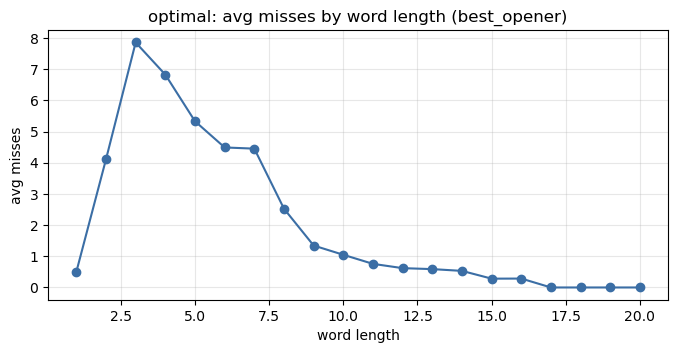

,length,avg misses
0,1,0.500
1,2,4.112
2,3,7.859
3,4,6.827
4,5,5.332
5,6,4.491
6,7,4.453
7,8,2.526
8,9,1.345
9,10,1.049


In [10]:
lengths = list(range(1, 21))
vals = []
for L in lengths:
    s = sview.make_strategy(STRATEGY, L, weighting=WEIGHTING, budget=BUDGET,
                            fill_capped=FILL_CAPPED)
    vals.append(s.headline_value() if s.available else np.nan)
metric = sv.headline_label() if sv.available else 'metric'

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lengths, vals, 'o-', color='#3b6ea5')
ax.set_xlabel('word length'); ax.set_ylabel(metric)
ax.set_title(f'{STRATEGY}: {metric} by word length ({WEIGHTING})')
ax.grid(alpha=0.3); plt.show()

def _fmt(v):
    return None if v is None or (isinstance(v, float) and np.isnan(v)) else round(v, 3)
pd.DataFrame({'length': lengths, metric: [_fmt(v) for v in vals]})